In [ ]:
# Install required libraries
!pip install albumentations opencv-python matplotlib torch torchvision numpy pillow scikit-learn tqdm timm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Weather Augmentation Module
import albumentations as A

def get_weather_transform():
    transform = A.Compose([
        A.RandomRain(p=0.3),
        A.RandomFog(p=0.3),
        A.RandomSnow(p=0.2),
        A.MotionBlur(p=0.3),
        A.RandomBrightnessContrast(p=0.4),
        A.GaussNoise(p=0.2)
    ])
    return transform

In [ ]:
# Image Enhancement Module
import cv2
import numpy as np

def clahe_enhancement(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)

    merged = cv2.merge((cl, a, b))
    enhanced = cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)

    return enhanced

def sharpen_image(image):
    kernel = np.array([[0,-1,0],
                       [-1,5,-1],
                       [0,-1,0]])
    return cv2.filter2D(image, -1, kernel)

In [ ]:
# Custom Dataset Loader (DFR Dataset) - Modified for ConvNeXt
import os
import cv2
import torch
from torch.utils.data import Dataset
from torchvision import transforms

class DFRDataset(Dataset):
    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.classes = os.listdir(root_dir)
        self.image_paths = []
        self.labels = []

        for label in self.classes:
            class_path = os.path.join(root_dir, label)
            for img in os.listdir(class_path):
                self.image_paths.append(os.path.join(class_path, img))
                self.labels.append(int(label))

        self.weather = get_weather_transform()

        # ConvNeXt was trained with ImageNet normalization (same as ResNet)
        # Using the same normalization as standard pretrained models
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((224, 224)),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.image_paths[idx])
        if img is None:
            print(f"Warning: Could not read image {self.image_paths[idx]}")
            # Return a placeholder or skip
            return self.__getitem__((idx + 1) % len(self.image_paths))

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Weather simulation
        img = self.weather(image=img)['image']

        # Enhancement
        img = clahe_enhancement(img)
        img = sharpen_image(img)

        img = self.transform(img)

        label = torch.tensor(self.labels[idx])

        return img, label

In [ ]:
# ConvNeXt Tiny Model for Traffic Sign Detection (COMPLETE FIX)
import torch
import torch.nn as nn
import torchvision.models as models

class ConvNeXt_TSD(nn.Module):
    def __init__(self, num_classes):
        super(ConvNeXt_TSD, self).__init__()

        # Load pretrained ConvNeXt Tiny
        # Using weights='DEFAULT' instead of deprecated pretrained=True
        self.backbone = models.convnext_tiny(weights='DEFAULT')

        # ConvNeXt Tiny architecture:
        # - features: convolutional backbone returns [B, 768, 7, 7] for 224x224 input
        # - original classifier: Sequential(LayerNorm2d, GlobalAvgPool, LayerNorm, Linear)

        # Remove the original classifier
        self.backbone.classifier = nn.Identity()

        # Add global average pooling to convert feature maps to vector
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Custom Classifier Head (similar to your successful ResNet50 design)
        self.classifier = nn.Sequential(
            nn.Flatten(),           # Flatten [B, 768, 1, 1] -> [B, 768]
            nn.Linear(768, 512),    # Reduce from 768 -> 512
            nn.ReLU(),
            nn.Dropout(0.4),         # Prevent overfitting
            nn.Linear(512, num_classes)  # Final classification layer
        )

    def forward(self, x):
        # Extract features using ConvNeXt backbone
        x = self.backbone(x)        # Shape: [batch_size, 768, 7, 7]

        # Apply global average pooling
        x = self.global_pool(x)      # Shape: [batch_size, 768, 1, 1]

        # Classify using custom head
        x = self.classifier(x)       # Shape: [batch_size, num_classes]

        return x

# Optional: Quick test to verify shapes
def test_model():
    model = ConvNeXt_TSD(num_classes=59)
    test_input = torch.randn(2, 3, 224, 224)  # Batch of 2 images
    output = model(test_input)
    print(f"Input shape: {test_input.shape}")
    print(f"Output shape: {output.shape}")
    print(f" Model works correctly!")
    return output

# Run test
if __name__ == "__main__":
    test_model()

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 59])
 Model works correctly!


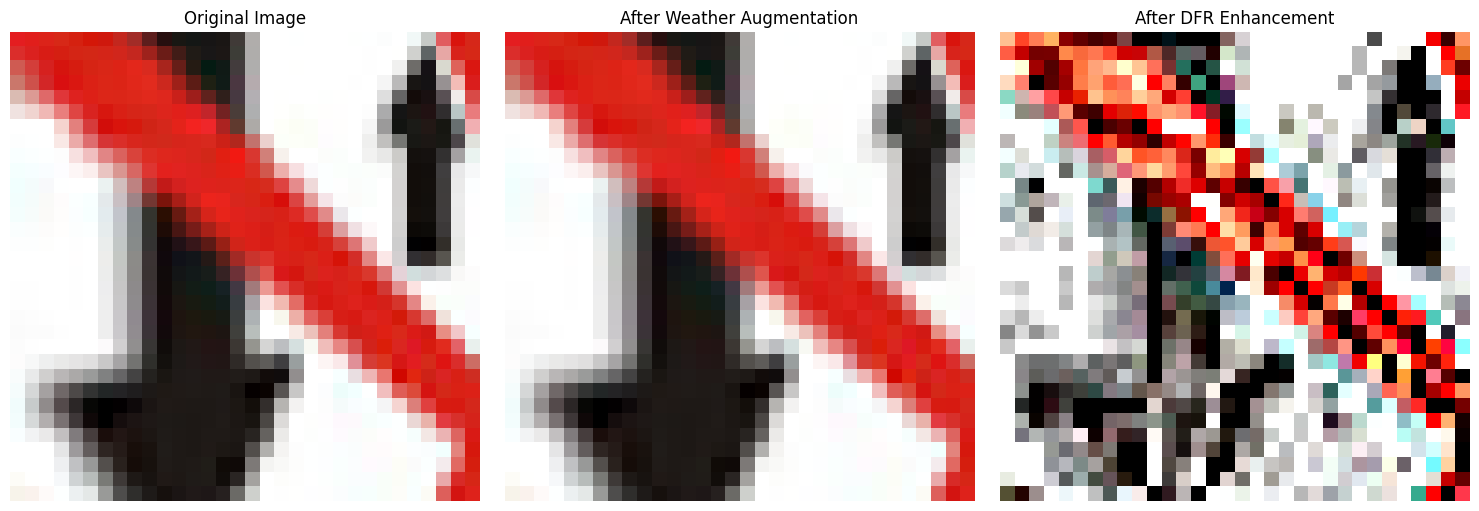

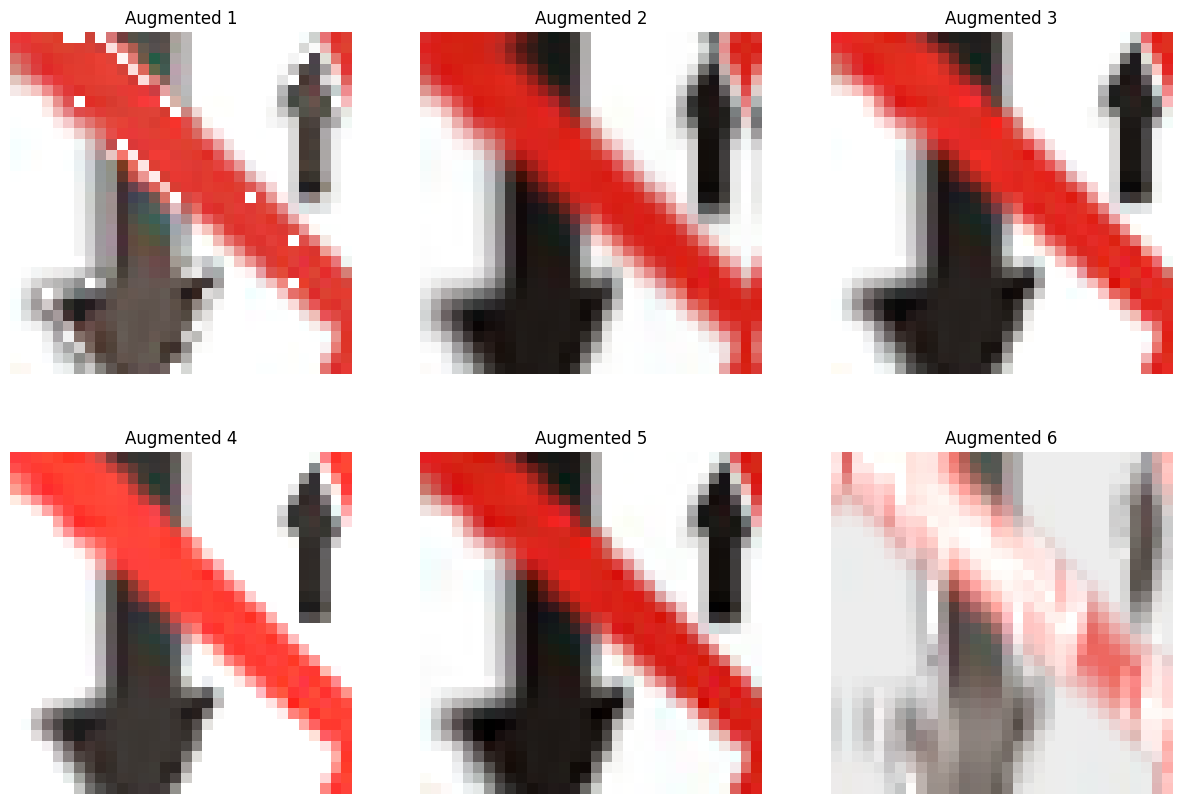

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load one sample image
image_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images/2/2_original_45.png_3a4dbe63-d8d9-4ec2-b91c-365cfdf37520.png"  # change to your image path
image = cv2.imread(image_path)
if image is not None:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Apply Weather Augmentation
    weather = get_weather_transform()
    augmented = weather(image=image)['image']

    # Apply Enhancement Block (DFR Module)
    enhanced = clahe_enhancement(augmented)
    enhanced = sharpen_image(enhanced)

    # Plot Results
    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(augmented)
    plt.title("After Weather Augmentation")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(enhanced)
    plt.title("After DFR Enhancement")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Show multiple augmentations
    plt.figure(figsize=(15,10))
    for i in range(6):
        augmented = weather(image=image)['image']
        plt.subplot(2,3,i+1)
        plt.imshow(augmented)
        plt.title(f"Augmented {i+1}")
        plt.axis("off")
    plt.show()
else:
    print(f"Could not load image from path: {image_path}")

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import matplotlib.pyplot as plt
import os
import time

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Load Dataset
dataset_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images"
if not os.path.exists(dataset_path):
    print(f"Error: Dataset path {dataset_path} does not exist!")
    # You can set an alternative path here
    # dataset_path = "/path/to/your/dataset"

dataset = DFRDataset(dataset_path)
print(f"Total images in dataset: {len(dataset)}")

# Split into Train & Validation (80-20)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

num_classes = 59  # Number of traffic sign classes

# Initialize ConvNeXt model
model = ConvNeXt_TSD(num_classes).to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0003)  # Same LR as ResNet50 success
# Add learning rate scheduler (same as VGG16 success)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

EPOCHS = 10  # Same as your previous successful runs

# Store history
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
best_val_acc = 0

print("Starting training with ConvNeXt Tiny...")
start_time = time.time()

for epoch in range(EPOCHS):
    # Training phase
    model.train()
    train_loss = 0
    correct = 0
    total = 0

    train_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]')
    for images, labels in train_bar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        # Calculate accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        # Update progress bar
        train_bar.set_postfix({'loss': loss.item(), 'acc': 100 * correct/total})

    train_accuracy = 100 * correct / total
    avg_train_loss = train_loss / len(train_loader)

    # Validation phase
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        val_bar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Val]')
        for images, labels in val_bar:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            val_bar.set_postfix({'loss': loss.item(), 'acc': 100 * correct/total})

    val_accuracy = 100 * correct / total
    avg_val_loss = val_loss / len(val_loader)

    # Update learning rate
    scheduler.step()

    # Store metrics
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_acc:
        best_val_acc = val_accuracy
        best_model_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/ConvNeXt_TSD_best.pth"
        os.makedirs(os.path.dirname(best_model_path), exist_ok=True)
        torch.save(model.state_dict(), best_model_path)
        print(f" Saved best model with validation accuracy: {val_accuracy:.2f}% (Epoch {epoch+1})")

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}%")
    print(f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")
    print(f"Current LR: {scheduler.get_last_lr()[0]:.6f}")
    print("-" * 60)

# Save final model
final_model_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/ConvNeXt_TSD_final.pth"
torch.save(model.state_dict(), final_model_path)

end_time = time.time()
training_time = end_time - start_time
print(f"\n Training completed in {training_time//60:.0f}m {training_time%60:.0f}s")
print(f"Best validation accuracy: {best_val_acc:.2f}%")

Using device: cuda
Total images in dataset: 13971
Total parameters: 28,242,587
Trainable parameters: 28,242,587
Starting training with ConvNeXt Tiny...


Epoch 1/10 [Val]: 100%|██████████| 88/88 [08:11<00:00,  5.59s/it, loss=1.2, acc=68.1]


 Saved best model with validation accuracy: 68.09% (Epoch 1)

Epoch [1/10]
Train Loss: 2.2835, Train Acc: 36.19%
Val Loss: 1.0051, Val Acc: 68.09%
Current LR: 0.000300
------------------------------------------------------------


Epoch 2/10 [Val]: 100%|██████████| 88/88 [00:28<00:00,  3.12it/s, loss=0.732, acc=78.8]


 Saved best model with validation accuracy: 78.82% (Epoch 2)

Epoch [2/10]
Train Loss: 0.8669, Train Acc: 72.47%
Val Loss: 0.6625, Val Acc: 78.82%
Current LR: 0.000300
------------------------------------------------------------


Epoch 3/10 [Val]: 100%|██████████| 88/88 [00:28<00:00,  3.13it/s, loss=0.5, acc=81.8]


... (11 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 88/88 [00:28<00:00,  3.12it/s, loss=0.472, acc=86]



Epoch [9/10]
Train Loss: 0.3944, Train Acc: 85.67%
Val Loss: 0.3868, Val Acc: 85.97%
Current LR: 0.000030
------------------------------------------------------------


Epoch 10/10 [Val]: 100%|██████████| 88/88 [00:28<00:00,  3.14it/s, loss=0.44, acc=85.9]



Epoch [10/10]
Train Loss: 0.3717, Train Acc: 86.28%
Val Loss: 0.3851, Val Acc: 85.90%
Current LR: 0.000003
------------------------------------------------------------

 Training completed in 75m 3s
Best validation accuracy: 86.01%


/tmp/ipykernel_2647/3678995915.py:15: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b-" (-> color='b'). The keyword argument will take precedence.
  ax1.plot(epochs, train_accuracies, 'b-', marker='o', linewidth=2, markersize=8,
/tmp/ipykernel_2647/3678995915.py:17: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax1.plot(epochs, val_accuracies, 'r-', marker='s', linewidth=2, markersize=8,
/tmp/ipykernel_2647/3678995915.py:34: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b-" (-> color='b'). The keyword argument will take precedence.
  ax2.plot(epochs, train_losses, 'b-', marker='o', linewidth=2, markersize=8,
/tmp/ipykernel_2647/3678995915.py:36: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument wi

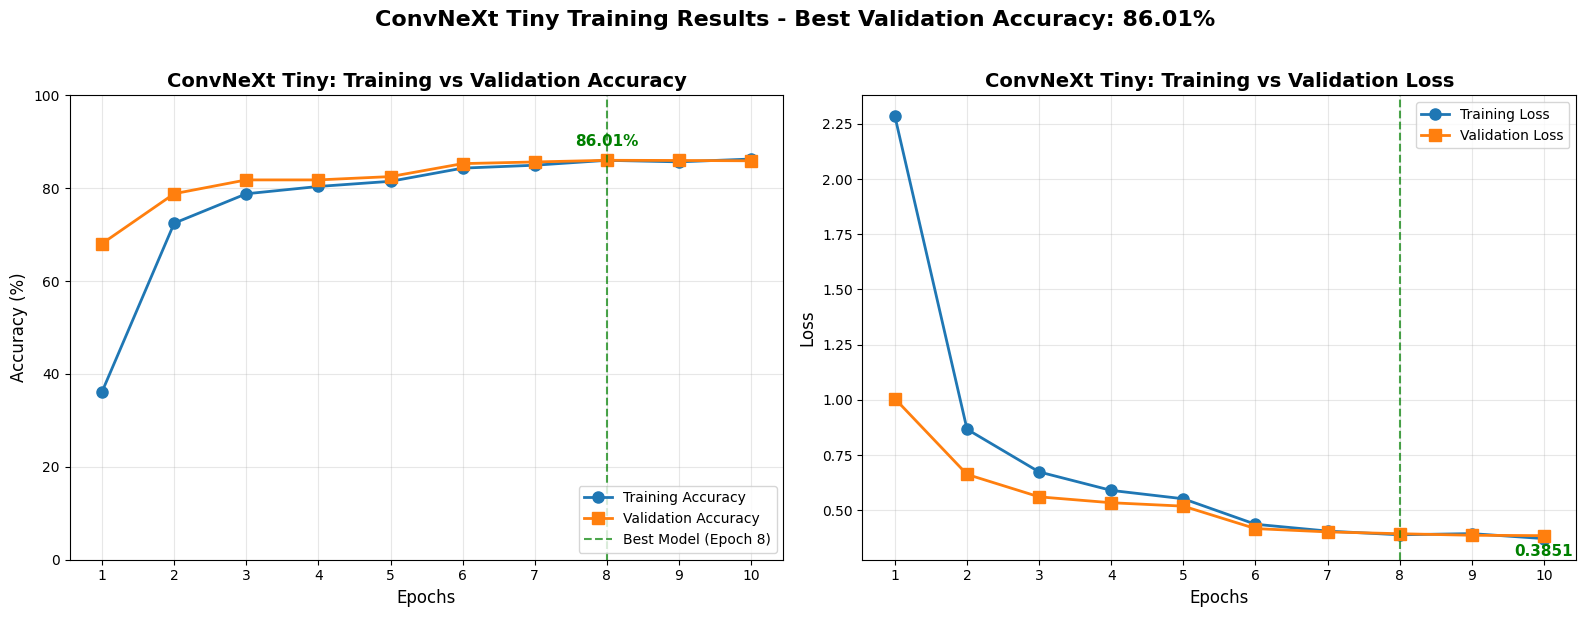

CONVNEXT TINY TRAINING SUMMARY
Total training time: 75m 3s
Best validation accuracy: 86.01% (Epoch 8)
Final validation accuracy: 85.90%
Final training accuracy: 86.28%
Best validation loss: 0.3851
Final validation loss: 0.3851


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Your data from training
epochs = list(range(1, len(train_accuracies) + 1))

# Find best epoch
best_epoch = np.argmax(val_accuracies) + 1
best_acc = max(val_accuracies)

# Create figure with 2 subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Accuracy
ax1.plot(epochs, train_accuracies, 'b-', marker='o', linewidth=2, markersize=8,
         label='Training Accuracy', color='#1f77b4')
ax1.plot(epochs, val_accuracies, 'r-', marker='s', linewidth=2, markersize=8,
         label='Validation Accuracy', color='#ff7f0e')
ax1.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7,
            label=f'Best Model (Epoch {best_epoch})')
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Accuracy (%)', fontsize=12)
ax1.set_title('ConvNeXt Tiny: Training vs Validation Accuracy', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10, loc='lower right')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(epochs)
ax1.set_ylim(0, 100)

# Add value label for best accuracy
ax1.annotate(f'{best_acc:.2f}%', (best_epoch, best_acc), textcoords="offset points",
             xytext=(0, 10), ha='center', fontsize=11, fontweight='bold', color='green')

# Plot 2: Loss
ax2.plot(epochs, train_losses, 'b-', marker='o', linewidth=2, markersize=8,
         label='Training Loss', color='#1f77b4')
ax2.plot(epochs, val_losses, 'r-', marker='s', linewidth=2, markersize=8,
         label='Validation Loss', color='#ff7f0e')
ax2.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7)
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('ConvNeXt Tiny: Training vs Validation Loss', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(epochs)

# Add value label for best loss
best_loss_idx = np.argmin(val_losses)
ax2.annotate(f'{min(val_losses):.4f}', (best_loss_idx + 1, min(val_losses)),
             textcoords="offset points", xytext=(0, -15), ha='center',
             fontsize=11, fontweight='bold', color='green')

plt.suptitle(f'ConvNeXt Tiny Training Results - Best Validation Accuracy: {best_acc:.2f}%',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*60)
print("CONVNEXT TINY TRAINING SUMMARY")
print("="*60)
print(f"Total training time: {training_time//60:.0f}m {training_time%60:.0f}s")
print(f"Best validation accuracy: {best_acc:.2f}% (Epoch {best_epoch})")
print(f"Final validation accuracy: {val_accuracies[-1]:.2f}%")
print(f"Final training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Best validation loss: {min(val_losses):.4f}")
print(f"Final validation loss: {val_losses[-1]:.4f}")
print("="*60)

 Class names loaded successfully
Total classes: 59
Using device: cuda
 Model loaded successfully!

 Predicted Class: 10
 Sign Name: No entry for motor vehicles
 Confidence: 100.00%

 Top 5 Predictions:
   1. Class 10: No entry for motor vehicles (100.00%)
   2. Class 32: Loose gravel (0.00%)
   3. Class 9: No entry for hand carts (0.00%)
   4. Class 5: No entry for cycles (0.00%)
   5. Class 16: No right turn (0.00%)


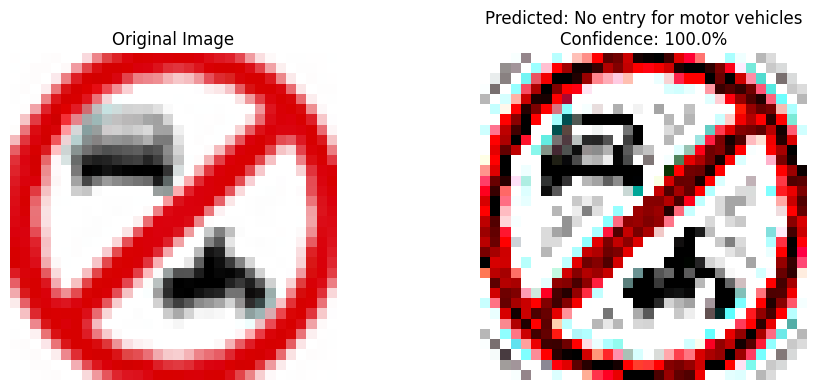

In [ ]:
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load class names from CSV
csv_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/traffic_sign.csv"  # Update path if needed

try:
    df = pd.read_csv(csv_path)
    class_names = dict(zip(df['ClassId'], df['Name']))
    print(" Class names loaded successfully")
    print(f"Total classes: {len(class_names)}")
except Exception as e:
    print(f" Could not load CSV: {e}")
    # Fallback if CSV not found
    class_names = {i: f"Class {i}" for i in range(59)}
    print("Using default class names")

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Load the trained ConvNeXt model
model = ConvNeXt_TSD(num_classes=59)
model_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/ConvNeXt_TSD_best.pth"  # Using best model

if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model = model.to(DEVICE)
    model.eval()
    print(" Model loaded successfully!")
else:
    print(f" Model not found at {model_path}")
    # Try final model if best doesn't exist
    model_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/models/ConvNeXt_TSD_final.pth"
    if os.path.exists(model_path):
        model.load_state_dict(torch.load(model_path, map_location=DEVICE))
        model = model.to(DEVICE)
        model.eval()
        print(" Final model loaded successfully!")
    else:
        print(" No model found!")

# Define the same transform used during training
from torchvision import transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                       std=[0.229, 0.224, 0.225])
])

# Load and preprocess test image
test_image_path = "/content/drive/MyDrive/SEM-8 MAJOR PROJECT/Images/10/10_original_53.png_4c22912b-12d5-42b8-85fa-76f36b51f445.png"

if os.path.exists(test_image_path):
    image = cv2.imread(test_image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Apply DFR Enhancement
    enhanced = clahe_enhancement(image_rgb)
    enhanced = sharpen_image(enhanced)

    # Transform for model
    image_tensor = transform(enhanced).unsqueeze(0).to(DEVICE)

    # Inference
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)
        confidence, prediction = torch.max(probabilities, dim=1)

    pred_class = prediction.item()
    confidence_score = confidence.item() * 100

    print(f"\n Predicted Class: {pred_class}")
    print(f" Sign Name: {class_names.get(pred_class, 'Unknown')}")
    print(f" Confidence: {confidence_score:.2f}%")

    # Show top 5 predictions
    top5_prob, top5_classes = torch.topk(probabilities, 5)
    print("\n Top 5 Predictions:")
    for i in range(5):
        class_id = top5_classes[0][i].item()
        prob = top5_prob[0][i].item() * 100
        sign_name = class_names.get(class_id, 'Unknown')
        print(f"   {i+1}. Class {class_id}: {sign_name} ({prob:.2f}%)")

    # Display image
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced)
    plt.title(f"Predicted: {class_names.get(pred_class, 'Unknown')}\nConfidence: {confidence_score:.1f}%")
    plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print(f" Could not load image from path: {test_image_path}")
    print("Please update the test_image_path variable with a valid image path.")